In [3]:
import pandas as pd
import numpy as np
import sklearn
import networkx as nx

print("pandas", pd.__version__)
print("numpy", np.__version__)
print("scikit-learn", sklearn.__version__)
print("networkx", nx.__version__)
print("All good!")

pandas 3.1.1
numpy 2.5.5
scikit-learn 1.9.1
networkx 3.7
All good!


In [1]:
import os
DATA_DIR = "data/"
print(os.listdir(DATA_DIR))

['.DS_Store', 'elliptic_txs_classes.csv', 'elliptic_txs_edgelist.csv', 'elliptic_txs_features.csv']


In [ ]:
import pandas as pd

feats = pd.read_csv(DATA_DIR + "elliptic_txs_features.csv", header=None)
classes = pd.read_csv(DATA_DIR + "elliptic_txs_classes.csv")
edges = pd.read_csv(DATA_DIR + "elliptic_txs_edgelist.csv")

feats = feats.rename(columns={0: "txId", 1: "time"})

print("Features shape:", feats.shape)
print("Classes shape:", classes.shape)
print("Edges shape:", edges.shape)

print("\nClass counts:")
print(classes["class"].value_counts())

print("\nTransactions per time step (first 10):")
print(feats["time"].value_counts().sort_index().head(10))

Features shape: (203769, 167)
Classes shape: (203769, 2)
Edges shape: (234355, 2)

Class counts:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64

Transactions per time step (first 10):
time
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support

# Merge features with labels; keep labeled only ('1' = illicit, '2' = licit)
df = feats.merge(classes, on="txId")
df = df[df["class"] != "unknown"].copy()
df["label"] = (df["class"] == "1").astype(int)

# Temporal split
train = df[df["time"] <= 34]
test = df[df["time"] > 34]
X_cols = [c for c in df.columns if c not in ("txId", "class", "label", "time")]

print("Train size:", len(train), "| illicit:", train["label"].sum())
print("Test size:", len(test), "| illicit:", test["label"].sum())

def evaluate(model, name):
    model.fit(train[X_cols], train["label"])
    pred = model.predict(test[X_cols])
    p, r, f1, _ = precision_recall_fscore_support(
        test["label"], pred, average="binary", pos_label=1
    )
    print(f"{name}: precision={p:.3f} recall={r:.3f} F1={f1:.3f}")

evaluate(LogisticRegression(max_iter=2000, class_weight="balanced"), "LogReg")
evaluate(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), "RandomForest")

Train size: 29894 | illicit: 3462
Test size: 16670 | illicit: 1083
LogReg: precision=0.192 recall=0.867 F1=0.314
RandomForest: precision=0.975 recall=0.722 F1=0.830


In [ ]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support
from xgboost import XGBClassifier

results = []

def run(model_fn, name, seeds=(0, 1, 2, 3, 4)):
    scores = []
    for s in seeds:
        m = model_fn(s)
        m.fit(train[X_cols], train["label"])
        pred = m.predict(test[X_cols])
        p, r, f1, _ = precision_recall_fscore_support(
            test["label"], pred, average="binary", pos_label=1
        )
        scores.append((p, r, f1))
    a = np.array(scores)
    mean, std = a.mean(axis=0), a.std(axis=0)
    print(f"{name}: P={mean[0]:.3f}±{std[0]:.3f}  R={mean[1]:.3f}±{std[1]:.3f}  F1={mean[2]:.3f}±{std[2]:.3f}")
    results.append({"model": name, "precision": mean[0], "recall": mean[1], "f1": mean[2], "f1_std": std[2]})

# Logistic Regression is deterministic, so one seed is enough
run(lambda s: make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=2000, class_weight="balanced")),
    "LogReg (scaled)", seeds=(0,))

run(lambda s: RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=-1),
    "RandomForest")

run(lambda s: XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                            random_state=s, n_jobs=-1, eval_metric="logloss"),
    "XGBoost")

import pandas as pd
res_df = pd.DataFrame(results)
res_df.to_csv(DATA_DIR + "baseline_results.csv", index=False)
res_df

LogReg (scaled): P=0.183±0.000  R=0.878±0.000  F1=0.303±0.000
RandomForest: P=0.964±0.001  R=0.721±0.002  F1=0.825±0.001
XGBoost: P=0.918±0.000  R=0.729±0.000  F1=0.813±0.000


,model,precision,recall,f1,f1_std
0,LogReg (scaled),0.182920,0.878116,0.302770,0.000000e+00
1,RandomForest,0.963707,0.720776,0.824722,1.090381e-03
2,XGBoost,0.917538,0.729455,0.812757,1.110223e-16


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_fscore_support
from xgboost import XGBClassifier

DATA_DIR = "/content/drive/MyDrive/crypto_paper/"
feats = pd.read_csv(DATA_DIR + "elliptic_txs_features.csv", header=None)
classes = pd.read_csv(DATA_DIR + "elliptic_txs_classes.csv")
edges = pd.read_csv(DATA_DIR + "elliptic_txs_edgelist.csv")
feats = feats.rename(columns={0: "txId", 1: "time"})

df = feats.merge(classes, on="txId")
df = df[df["class"] != "unknown"].copy()
df["label"] = (df["class"] == "1").astype(int)

train = df[df["time"] <= 34]
test = df[df["time"] > 34]
X_cols = [c for c in df.columns if c not in ("txId", "class", "label", "time")]
print("Train:", len(train), "| Test:", len(test))

Mounted at /content/drive
Train: 29894 | Test: 16670


In [ ]:
import networkx as nx

# Build the network from the edges file
G = nx.from_pandas_edgelist(edges, source="txId1", target="txId2",
                            create_using=nx.DiGraph())

# Features that describe the connections (they don't use any labels)
in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
pr = nx.pagerank(G)                              # takes about 1 minute
avg_nb = nx.average_neighbor_degree(G.to_undirected())

df["in_deg"] = df["txId"].map(in_deg).fillna(0)
df["out_deg"] = df["txId"].map(out_deg).fillna(0)
df["pagerank"] = df["txId"].map(pr).fillna(0)
df["avg_nb_deg"] = df["txId"].map(avg_nb).fillna(0)

graph_cols = ["in_deg", "out_deg", "pagerank", "avg_nb_deg"]
train = df[df["time"] <= 34]
test = df[df["time"] > 34]

def run_cols(model_fn, name, cols, seeds=(0, 1, 2, 3, 4)):
    scores = []
    for s in seeds:
        m = model_fn(s)
        m.fit(train[cols], train["label"])
        pred = m.predict(test[cols])
        p, r, f1, _ = precision_recall_fscore_support(
            test["label"], pred, average="binary", pos_label=1)
        scores.append((p, r, f1))
    a = np.array(scores)
    print(f"{name}: P={a[:,0].mean():.3f} R={a[:,1].mean():.3f} "
          f"F1={a[:,2].mean():.3f}±{a[:,2].std():.3f}")

rf_fn = lambda s: RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=-1)
run_cols(rf_fn, "RF base", X_cols)
run_cols(rf_fn, "RF base + graph", X_cols + graph_cols)

RF base: P=0.964 R=0.721 F1=0.825±0.001


TypeError: Feature names are only supported if all input features have string names, but your input has ['int', 'str'] as feature name / column name types. If you want feature names to be stored and validated, you must convert them all to strings, by using X.columns = X.columns.astype(str) for example. Otherwise you can remove feature / column names from your input data, or convert them all to a non-string data type.

In [ ]:
# 1. Saare column names ko text (string) bana do
df.columns = df.columns.astype(str)

# 2. Feature lists dobara banao
graph_cols = ["in_deg", "out_deg", "pagerank", "avg_nb_deg"]
X_cols = [c for c in df.columns
          if c not in ["txId", "class", "label", "time"] + graph_cols]

# 3. Train/test dobara banao (naye column names ke saath)
train = df[df["time"] <= 34]
test = df[df["time"] > 34]

print("Base features:", len(X_cols), "| Graph features:", len(graph_cols))

# 4. Comparison dobara chalao
run_cols(rf_fn, "RF base", X_cols)
run_cols(rf_fn, "RF base + graph", X_cols + graph_cols)

Base features: 165 | Graph features: 4
RF base: P=0.964 R=0.721 F1=0.825±0.001
RF base + graph: P=0.967 R=0.722 F1=0.827±0.002


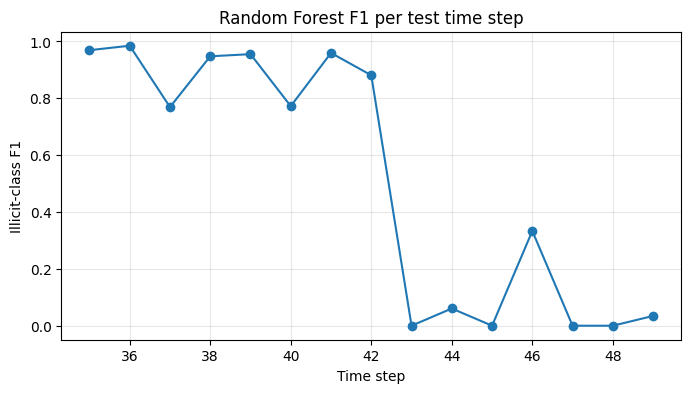

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(train[X_cols], train["label"])
t = test.copy()
t["pred"] = rf.predict(t[X_cols])

steps, f1s = [], []
for step, g in t.groupby("time"):
    if g["label"].sum() > 0:
        steps.append(step)
        f1s.append(f1_score(g["label"], g["pred"], pos_label=1))

plt.figure(figsize=(8, 4))
plt.plot(steps, f1s, marker="o")
plt.xlabel("Time step"); plt.ylabel("Illicit-class F1")
plt.title("Random Forest F1 per test time step")
plt.grid(alpha=0.3)
plt.savefig(DATA_DIR + "f1_per_timestep.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

print("Illicit count per test step:")
print(t.groupby("time")["label"].sum().to_string())

for name, g in [("Steps 35-42", t[t["time"] <= 42]),
                ("Steps 43-49", t[t["time"] >= 43])]:
    p, r, f1, _ = precision_recall_fscore_support(
        g["label"], g["pred"], average="binary", pos_label=1, zero_division=0)
    print(f"{name}: n={len(g)}, illicit={g['label'].sum()}, "
          f"P={p:.3f} R={r:.3f} F1={f1:.3f}")

Illicit count per test step:
time
35    182
36     33
37     40
38    111
39     81
40    112
41    116
42    239
43     24
44     24
45      5
46      2
47     22
48     36
49     56
Steps 35-42: n=9983, illicit=914, P=0.987 R=0.849 F1=0.913
Steps 43-49: n=6687, illicit=169, P=0.143 R=0.018 F1=0.032


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_fscore_support
from xgboost import XGBClassifier

final = []
early_mask = (test["time"] <= 42).values

def run_final(model_fn, name, cols, seeds=(0, 1, 2, 3, 4)):
    rows = []
    for s in seeds:
        m = model_fn(s)
        m.fit(train[cols], train["label"])
        pred = m.predict(test[cols])
        res = []
        for mask in (np.ones(len(test), dtype=bool), early_mask, ~early_mask):
            p, r, f1, _ = precision_recall_fscore_support(
                test["label"].values[mask], pred[mask],
                average="binary", pos_label=1, zero_division=0)
            res += [p, r, f1]
        rows.append(res)
    a = np.array(rows)
    mean, std = a.mean(axis=0), a.std(axis=0)
    print(f"{name}: F1 all={mean[2]:.3f}±{std[2]:.3f} | "
          f"F1 35-42={mean[5]:.3f} | F1 43-49={mean[8]:.3f}")
    final.append({"model": name,
                  "precision": mean[0], "recall": mean[1],
                  "f1": mean[2], "f1_std": std[2],
                  "f1_35_42": mean[5], "f1_43_49": mean[8]})

lr_fn  = lambda s: make_pipeline(StandardScaler(),
                                 LogisticRegression(max_iter=2000, class_weight="balanced"))
rf_fn  = lambda s: RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=-1)
xgb_fn = lambda s: XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                 subsample=0.8, colsample_bytree=0.8,
                                 random_state=s, n_jobs=-1, eval_metric="logloss")

all_cols = X_cols + graph_cols

run_final(lr_fn,  "LogReg (base)",         X_cols,   seeds=(0,))
run_final(lr_fn,  "LogReg (+graph)",       all_cols, seeds=(0,))
run_final(rf_fn,  "RandomForest (base)",   X_cols)
run_final(rf_fn,  "RandomForest (+graph)", all_cols)
run_final(xgb_fn, "XGBoost (base)",        X_cols)
run_final(xgb_fn, "XGBoost (+graph)",      all_cols)

final_df = pd.DataFrame(final)
final_df.to_csv(DATA_DIR + "final_results.csv", index=False)
final_df

LogReg (base): F1 all=0.303±0.000 | F1 35-42=0.413 | F1 43-49=0.097
LogReg (+graph): F1 all=0.304±0.000 | F1 35-42=0.405 | F1 43-49=0.113
RandomForest (base): F1 all=0.825±0.001 | F1 35-42=0.913 | F1 43-49=0.032
RandomForest (+graph): F1 all=0.827±0.002 | F1 35-42=0.914 | F1 43-49=0.032
XGBoost (base): F1 all=0.816±0.002 | F1 35-42=0.910 | F1 43-49=0.033
XGBoost (+graph): F1 all=0.812±0.003 | F1 35-42=0.909 | F1 43-49=0.028


,model,precision,recall,f1,f1_std,f1_35_42,f1_43_49
0,LogReg (base),0.182955,0.878116,0.302818,0.000000,0.412799,0.096936
1,LogReg (+graph),0.183610,0.877193,0.303660,0.000000,0.405194,0.113103
2,RandomForest (base),0.963707,0.720776,0.824722,0.001090,0.913212,0.031583
3,RandomForest (+graph),0.967193,0.722438,0.827068,0.001819,0.914363,0.032058
4,XGBoost (base),0.927724,0.727608,0.815565,0.002207,0.910102,0.032611
5,XGBoost (+graph),0.919153,0.727608,0.812216,0.002861,0.908673,0.028237


In [ ]:
import matplotlib.pyplot as plt

rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(train[all_cols], train["label"])

imp = pd.Series(rf.feature_importances_, index=all_cols).sort_values(ascending=False)

top = imp.head(15)
plt.figure(figsize=(8, 5))
top[::-1].plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 15 features (Random Forest)")
plt.tight_layout()
plt.savefig(DATA_DIR + "feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

ranks = {c: int(imp.index.get_loc(c)) + 1 for c in graph_cols}
print("Rank of graph features (out of", len(imp), "):", ranks)


NameError: name 'RandomForestClassifier' is not defined

Mounted at /content/drive
Train: 29894 | Test: 16670 | Features: 169


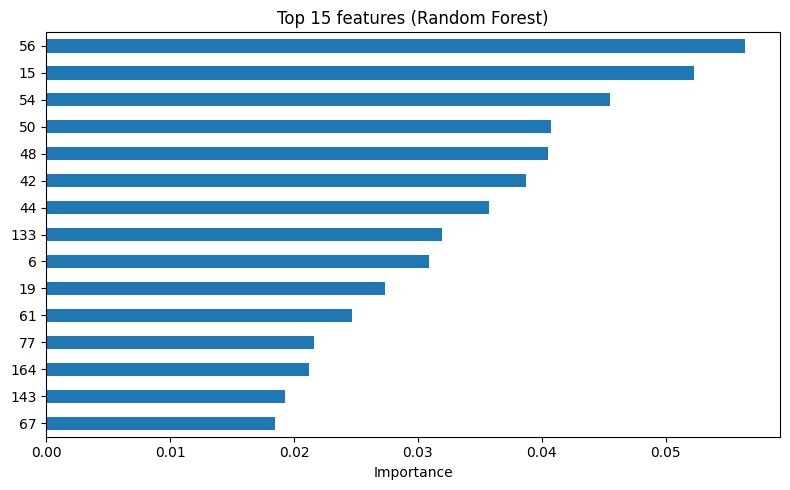

Rank of graph features (out of 169 ): {'in_deg': 134, 'out_deg': 142, 'pagerank': 103, 'avg_nb_deg': 104}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Data load
DATA_DIR = "/content/drive/MyDrive/crypto_paper/"
feats = pd.read_csv(DATA_DIR + "elliptic_txs_features.csv", header=None)
classes = pd.read_csv(DATA_DIR + "elliptic_txs_classes.csv")
edges = pd.read_csv(DATA_DIR + "elliptic_txs_edgelist.csv")
feats = feats.rename(columns={0: "txId", 1: "time"})

df = feats.merge(classes, on="txId")
df = df[df["class"] != "unknown"].copy()
df["label"] = (df["class"] == "1").astype(int)

# 2. Graph features (PageRank mein 1-2 minute lagte hain)
G = nx.from_pandas_edgelist(edges, source="txId1", target="txId2",
                            create_using=nx.DiGraph())
df["in_deg"] = df["txId"].map(dict(G.in_degree())).fillna(0)
df["out_deg"] = df["txId"].map(dict(G.out_degree())).fillna(0)
df["pagerank"] = df["txId"].map(nx.pagerank(G)).fillna(0)
df["avg_nb_deg"] = df["txId"].map(nx.average_neighbor_degree(G.to_undirected())).fillna(0)

# 3. Column names ko text banao, aur lists/split banao
df.columns = df.columns.astype(str)
graph_cols = ["in_deg", "out_deg", "pagerank", "avg_nb_deg"]
X_cols = [c for c in df.columns
          if c not in ["txId", "class", "label", "time"] + graph_cols]
all_cols = X_cols + graph_cols
train = df[df["time"] <= 34]
test = df[df["time"] > 34]
print("Train:", len(train), "| Test:", len(test), "| Features:", len(all_cols))

# 4. Feature importance
rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(train[all_cols], train["label"])
imp = pd.Series(rf.feature_importances_, index=all_cols).sort_values(ascending=False)

top = imp.head(15)
plt.figure(figsize=(8, 5))
top[::-1].plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 15 features (Random Forest)")
plt.tight_layout()
plt.savefig(DATA_DIR + "feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

ranks = {c: int(imp.index.get_loc(c)) + 1 for c in graph_cols}
print("Rank of graph features (out of", len(imp), "):", ranks)

In [2]:
import joblib, sklearn
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(train[X_cols], train["label"])
joblib.dump(rf, DATA_DIR + "rf_model.joblib", compress=3)

# Demo ke liye test set se chhota sample (illicit + licit mix)
demo = pd.concat([
    test[test["label"] == 1].sample(150, random_state=0),
    test[test["label"] == 0].sample(350, random_state=0),
])[["txId", "time", "label"] + X_cols]
demo.to_csv(DATA_DIR + "demo_data.csv", index=False)

print("scikit-learn version:", sklearn.__version__)

NameError: name 'train' is not defined

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import joblib, sklearn
from sklearn.ensemble import RandomForestClassifier

DATA_DIR = "/content/drive/MyDrive/crypto_paper/"
feats = pd.read_csv(DATA_DIR + "elliptic_txs_features.csv", header=None)
classes = pd.read_csv(DATA_DIR + "elliptic_txs_classes.csv")
feats = feats.rename(columns={0: "txId", 1: "time"})
feats.columns = feats.columns.astype(str)

df = feats.merge(classes, on="txId")
df = df[df["class"] != "unknown"].copy()
df["label"] = (df["class"] == "1").astype(int)

train = df[df["time"] <= 34]
test = df[df["time"] > 34]
X_cols = [c for c in df.columns if c not in ("txId", "class", "label", "time")]
print("Train:", len(train), "| Test:", len(test), "| Features:", len(X_cols))

rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(train[X_cols], train["label"])
joblib.dump(rf, DATA_DIR + "rf_model.joblib", compress=3)

demo = pd.concat([
    test[test["label"] == 1].sample(150, random_state=0),
    test[test["label"] == 0].sample(350, random_state=0),
])[["txId", "time", "label"] + X_cols]
demo.to_csv(DATA_DIR + "demo_data.csv", index=False)

print("scikit-learn version:", sklearn.__version__)
print("Model size (MB):", round(os.path.getsize(DATA_DIR + "rf_model.joblib") / 1e6, 1))

Mounted at /content/drive
Train: 29894 | Test: 16670 | Features: 165
scikit-learn version: 1.6.1
Model size (MB): 1.5


In [4]:
import os
import pandas as pd
import joblib, sklearn
from sklearn.ensemble import RandomForestClassifier

DATA_DIR = "data/"
feats = pd.read_csv(DATA_DIR + "elliptic_txs_features.csv", header=None)
classes = pd.read_csv(DATA_DIR + "elliptic_txs_classes.csv")
feats = feats.rename(columns={0: "txId", 1: "time"})
feats.columns = feats.columns.astype(str)

df = feats.merge(classes, on="txId")
df = df[df["class"] != "unknown"].copy()
df["label"] = (df["class"] == "1").astype(int)

train = df[df["time"] <= 34]
test = df[df["time"] > 34]
X_cols = [c for c in df.columns if c not in ("txId", "class", "label", "time")]
print("Train:", len(train), "| Test:", len(test), "| Features:", len(X_cols))

rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(train[X_cols], train["label"])
joblib.dump(rf, "rf_model.joblib", compress=3)

demo = pd.concat([
    test[test["label"] == 1].sample(150, random_state=0),
    test[test["label"] == 0].sample(350, random_state=0),
])[["txId", "time", "label"] + X_cols]
demo.to_csv("demo_data.csv", index=False)

print("scikit-learn version:", sklearn.__version__)
print("Model size (MB):", round(os.path.getsize("rf_model.joblib") / 1e6, 1))

Train: 29894 | Test: 16670 | Features: 165
scikit-learn version: 1.9.1
Model size (MB): 1.5


In [5]:
import pandas as pd
import joblib
from sklearn.ensemble import RandomForestClassifier

DATA_DIR = "data/"
feats = pd.read_csv(DATA_DIR + "elliptic_txs_features.csv", header=None)
classes = pd.read_csv(DATA_DIR + "elliptic_txs_classes.csv")
feats = feats.rename(columns={0: "txId", 1: "time"})
feats.columns = feats.columns.astype(str)

df = feats.merge(classes, on="txId")
X_cols = [c for c in df.columns if c not in ("txId", "class", "time")]

labeled = df[df["class"] != "unknown"].copy()
labeled["label"] = (labeled["class"] == "1").astype(int)
unknown = df[df["class"] == "unknown"].copy()
print("Labeled:", len(labeled), "| Unknown:", len(unknown), "| Features:", len(X_cols))

# Final model: saare labeled data par train
final_rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
final_rf.fit(labeled[X_cols], labeled["label"])
joblib.dump(final_rf, "rf_final.joblib", compress=3)

# Unlabeled transactions ko score karo
unknown["prob_illicit"] = final_rf.predict_proba(unknown[X_cols])[:, 1]
scores = (unknown[["txId", "time", "prob_illicit"]]
          .sort_values("prob_illicit", ascending=False))
scores["prob_illicit"] = scores["prob_illicit"].round(4)
scores.to_csv("unknown_scores.csv", index=False)

print("Scored:", len(scores))
print("Prob >= 0.5:", (scores["prob_illicit"] >= 0.5).sum())
print("Prob >= 0.8:", (scores["prob_illicit"] >= 0.8).sum())

Labeled: 46564 | Unknown: 157205 | Features: 165
Scored: 157205
Prob >= 0.5: 7277
Prob >= 0.8: 3692


In [6]:
import shutil
import joblib

# 1. Trace graph ke liye: har transaction ka status aur score
nodes = df[["txId", "time", "class"]].copy()
nodes["status"] = nodes["class"].map({"1": "illicit", "2": "licit", "unknown": "unknown"})
nodes = nodes.merge(unknown[["txId", "prob_illicit"]], on="txId", how="left")
nodes["prob_illicit"] = nodes["prob_illicit"].round(4)
nodes[["txId", "time", "status", "prob_illicit"]].to_csv("nodes.csv", index=False)
shutil.copy("data/elliptic_txs_edgelist.csv", "edges.csv")

# 2. Drift explorer ke liye: paper wale model (steps 1-34) ki test predictions
rf34 = joblib.load("rf_model.joblib")
test_l = labeled[labeled["time"] > 34]
tp = test_l[["txId", "time", "label"]].copy()
tp["prob"] = rf34.predict_proba(test_l[X_cols])[:, 1].round(4)
tp.to_csv("test_predictions.csv", index=False)

print("nodes:", len(nodes), "| test predictions:", len(tp))

nodes: 203769 | test predictions: 16670


In [7]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support

def fit_rf(d):
    m = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
    m.fit(d[X_cols], d["label"])
    return m

names = ["static (train 1-34)", "expanding (all past steps)", "sliding (last 10 steps)"]
preds = {n: [] for n in names}
truth, times = [], []

static_model = fit_rf(labeled[labeled["time"] <= 34])

for t in range(35, 50):
    cur = labeled[labeled["time"] == t]
    if len(cur) == 0:
        continue
    truth.append(cur["label"].values)
    times.append(cur["time"].values)
    preds[names[0]].append(static_model.predict(cur[X_cols]))

    past = labeled[labeled["time"] < t]
    preds[names[1]].append(fit_rf(past).predict(cur[X_cols]))

    win = labeled[(labeled["time"] < t) & (labeled["time"] >= t - 10)]
    preds[names[2]].append(fit_rf(win).predict(cur[X_cols]))
    print("done step", t)

y = np.concatenate(truth)
tm = np.concatenate(times)
rows = []
for name, plist in preds.items():
    p_all = np.concatenate(plist)
    for period, mask in [("35-49", tm >= 35), ("35-42", tm <= 42), ("43-49", tm >= 43)]:
        p, r, f, _ = precision_recall_fscore_support(
            y[mask], p_all[mask], average="binary", pos_label=1, zero_division=0)
        rows.append({"strategy": name, "period": period,
                     "precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)})

res = pd.DataFrame(rows)
res.to_csv("drift_mitigation.csv", index=False)
print(res.pivot(index="strategy", columns="period", values="f1"))

done step 35
done step 36
done step 37
done step 38
done step 39
done step 40
done step 41
done step 42
done step 43
done step 44
done step 45
done step 46
done step 47
done step 48
done step 49
period                      35-42  35-49  43-49
strategy                                       
expanding (all past steps)  0.915  0.843  0.215
sliding (last 10 steps)     0.898  0.818  0.087
static (train 1-34)         0.913  0.828  0.033


In [8]:
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support

def fit_rf(d, seed):
    m = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1)
    m.fit(d[X_cols], d["label"])
    return m

SEEDS = [0, 1, 2]
STRATS = ["static", "expanding", "sliding"]
steps = [t for t in range(35, 50) if (labeled["time"] == t).any()]
cur_list = [labeled[labeled["time"] == t] for t in steps]
y = np.concatenate([c["label"].values for c in cur_list])
tm = np.concatenate([c["time"].values for c in cur_list])
ids = np.concatenate([c["txId"].values for c in cur_list])

rows, saved = [], {}
for seed in SEEDS:
    probs = {s: [] for s in STRATS}
    static_model = fit_rf(labeled[labeled["time"] <= 34], seed)
    for t, cur in zip(steps, cur_list):
        probs["static"].append(static_model.predict_proba(cur[X_cols])[:, 1])
        past = labeled[labeled["time"] < t]
        probs["expanding"].append(fit_rf(past, seed).predict_proba(cur[X_cols])[:, 1])
        win = labeled[(labeled["time"] < t) & (labeled["time"] >= t - 10)]
        probs["sliding"].append(fit_rf(win, seed).predict_proba(cur[X_cols])[:, 1])
        print(f"seed {seed} | step {t} done")
    for s in STRATS:
        p_all = np.concatenate(probs[s])
        if seed == 0:
            saved[s] = p_all
        pred = (p_all > 0.5).astype(int)
        for period, mask in [("35-42", tm <= 42), ("35-49", tm >= 35), ("43-49", tm >= 43)]:
            p, r, f, _ = precision_recall_fscore_support(
                y[mask], pred[mask], average="binary", pos_label=1, zero_division=0)
            rows.append({"seed": seed, "strategy": s, "period": period,
                         "precision": p, "recall": r, "f1": f})

res = pd.DataFrame(rows)
res.to_csv("drift_mitigation_seeds.csv", index=False)

for s in STRATS:
    parts = []
    for per in ["35-42", "35-49", "43-49"]:
        v = res[(res["strategy"] == s) & (res["period"] == per)]["f1"]
        parts.append(f"{per}: {v.mean():.3f}±{v.std(ddof=0):.3f}")
    print(f"{s:10s}", " | ".join(parts))

# App ke liye: seed 0 ki probabilities
pd.DataFrame({"txId": ids, "time": tm, "label": y,
              **{f"prob_{s}": np.round(saved[s], 4) for s in STRATS}}
             ).to_csv("strategy_predictions.csv", index=False)
print("saved strategy_predictions.csv")

seed 0 | step 35 done
seed 0 | step 36 done
seed 0 | step 37 done
seed 0 | step 38 done
seed 0 | step 39 done
seed 0 | step 40 done
seed 0 | step 41 done
seed 0 | step 42 done
seed 0 | step 43 done
seed 0 | step 44 done
seed 0 | step 45 done
seed 0 | step 46 done
seed 0 | step 47 done
seed 0 | step 48 done
seed 0 | step 49 done
seed 1 | step 35 done
seed 1 | step 36 done
seed 1 | step 37 done
seed 1 | step 38 done
seed 1 | step 39 done
seed 1 | step 40 done
seed 1 | step 41 done
seed 1 | step 42 done
seed 1 | step 43 done
seed 1 | step 44 done
seed 1 | step 45 done
seed 1 | step 46 done
seed 1 | step 47 done
seed 1 | step 48 done
seed 1 | step 49 done
seed 2 | step 35 done
seed 2 | step 36 done
seed 2 | step 37 done
seed 2 | step 38 done
seed 2 | step 39 done
seed 2 | step 40 done
seed 2 | step 41 done
seed 2 | step 42 done
seed 2 | step 43 done
seed 2 | step 44 done
seed 2 | step 45 done
seed 2 | step 46 done
seed 2 | step 47 done
seed 2 | step 48 done
seed 2 | step 49 done
static    